# 🎓 第7章 第2课：Smart Beta 与因子择时

**本节目标**：

1. 用多因子复合分数构建 Smart Beta 组合，比较等权/分数加权/基准；
2. 用“趋势信号”做因子择时，看看择时是否真的有用。

对应原书第7章 Smart Beta 与因子择时部分。

> ⚠️ 示例面板为教学数据；结果仅演示方法，不代表真实 A 股结论。

In [1]:
import sys
from pathlib import Path

def _find_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / 'src' / 'factor_zero').exists():
            return p
    raise FileNotFoundError('找不到仓库根目录，请从仓库内启动 notebook')
ROOT = _find_root()
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from factor_zero.data import load_ashare_panel
from factor_zero.factors import build_factor_returns
from factor_zero.anomalies import rolling_ivol
from factor_zero.portfolio import (
    FACTOR_ORDER, build_style_exposures, factor_covariance,
    specific_variance, portfolio_risk, min_variance_weights,
    max_sharpe_weights, style_regression, smart_beta_weights,
)
from factor_zero.statistics import factor_summary, nw_t_stat

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC', 'DejaVu Sans']
print('✅ 环境就绪，开始学习！')

✅ 环境就绪，开始学习！


## 1) 多因子复合分数

```
score = z(BM) + z(ROE) + z(动量) − z(换手率) − z(投资)
```

方向：价值、质量、动量越高越好；换手率、投资越低越好。
每月选分数最高的 20% 股票，分别用等权和分数加权，持有下个月。

In [2]:
panel = load_ashare_panel()
ret = panel['ret']
factors = build_factor_returns(panel, n_groups=10)
def z(df):
    return df.sub(df.mean(axis=1), axis=0).div(df.std(axis=1), axis=0)
score = z(panel['bm']) + z(panel['roe']) + z(panel['momentum']) - z(panel['turnover']) - z(panel['investment'])
print('复合分数面板:', score.shape, '| 有效观测:', int(score.notna().sum().sum()))

复合分数面板: (83, 81) | 有效观测: 5751


In [3]:
dates = ret.index
p_eq, p_score, p_bench = [], [], []
for t in range(len(dates) - 1):
    d, dn = dates[t], dates[t + 1]
    s = score.loc[d].dropna()
    if len(s) < 20:
        continue
    top = s.sort_values(ascending=False).head(max(10, int(len(s) * 0.2))).index
    w_eq = smart_beta_weights(s.loc[top], method='equal')
    w_score = smart_beta_weights(s.loc[top], method='score')
    p_eq.append(float((ret.loc[dn, top] * w_eq).sum()))
    p_score.append(float((ret.loc[dn, top] * w_score).sum()))
    p_bench.append(float(ret.loc[dn].mean()))
idx = dates[1:1 + len(p_eq)]
port = pd.DataFrame({'等权SmartBeta': p_eq, '分数加权SmartBeta': p_score, '等权基准': p_bench}, index=idx)
pd.DataFrame({c: factor_summary(port[c]) for c in port.columns}).T.round(4)

,mean_ann,vol_ann,sharpe,t_stat,max_drawdown,win_rate
等权SmartBeta,0.1809,0.1761,1.0276,2.7514,-0.1666,0.6429
分数加权SmartBeta,0.2234,0.1958,1.1409,3.2573,-0.1538,0.6429
等权基准,0.1772,0.1968,0.9006,2.3800,-0.1987,0.5571


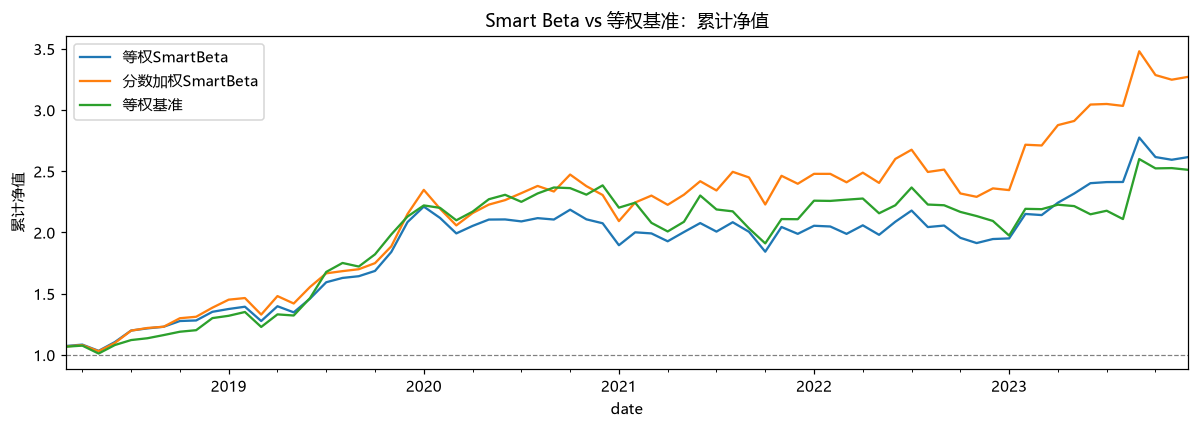

In [4]:
((1 + port).cumprod()).plot(figsize=(11, 4), title='Smart Beta vs 等权基准：累计净值')
plt.axhline(1, color='gray', lw=.8, ls='--'); plt.ylabel('累计净值')
plt.legend(); plt.tight_layout(); plt.show()

## 2) 因子择时：趋势信号有用吗？

规则：如果某因子过去 12 个月均值为正，下个月持有该因子；否则空仓（收益 0）。
对比“一直持有”的买入持有。

In [5]:
signals = (factors.rolling(12).mean().shift(1) > 0).astype(float)
timing = factors * signals
rows = {}
for col in factors.columns:
    bh = factor_summary(factors[col].dropna())
    tm = factor_summary(timing[col].dropna())
    rows[col] = {
        '买入持有年化': bh.get('mean_ann', np.nan),
        '择时年化': tm.get('mean_ann', np.nan),
        '买入持有t': bh.get('t_stat', np.nan),
        '择时t': tm.get('t_stat', np.nan),
    }
pd.DataFrame(rows).T.round(4)

,买入持有年化,择时年化,买入持有t,择时t
MKT,0.0986,0.0784,1.6306,1.7448
SMB,0.2510,0.2475,2.0356,2.4581
HML,-0.2082,-0.0598,-2.1130,-1.7831
WML,0.1957,0.0225,1.4069,0.1751
RMW,0.1009,0.1266,1.1690,1.9368
CMA,0.0297,0.0714,0.4578,1.6828
TURN,-0.0533,0.1092,-0.4272,1.3584


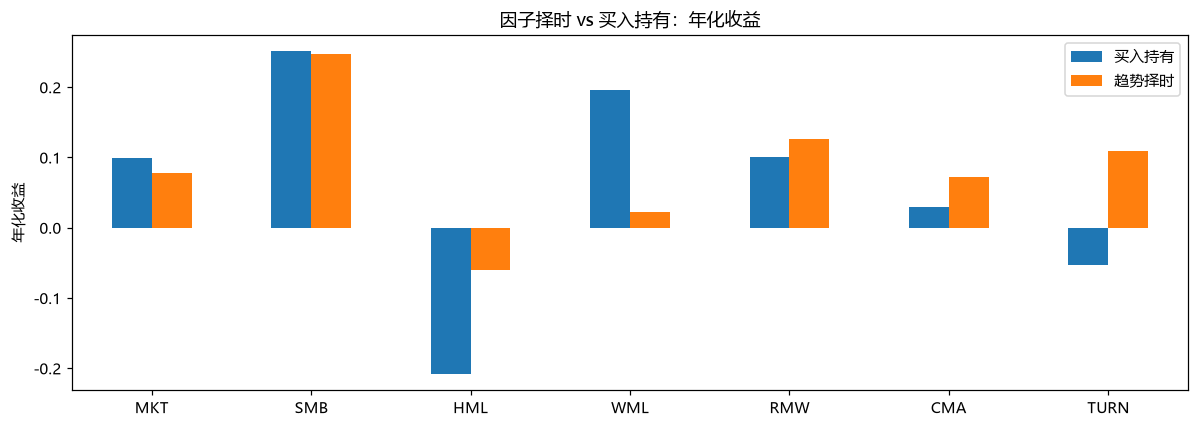

In [6]:
compare = pd.DataFrame({
    '买入持有': [factor_summary(factors[c].dropna()).get('mean_ann', np.nan) for c in factors.columns],
    '趋势择时': [factor_summary(timing[c].dropna()).get('mean_ann', np.nan) for c in factors.columns],
}, index=factors.columns)
compare.plot(kind='bar', figsize=(11, 4), title='因子择时 vs 买入持有：年化收益')
plt.ylabel('年化收益'); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## ✋ 试一试

1. 把选股比例从 20% 改成 10%/30%，组合表现怎么变？
2. 把复合分数里的动量去掉，Smart Beta 的结果变了吗？
3. 把择时信号从 12 个月改成 6 个月，择时表现更好还是更差？

## ✅ 本节小结

- Smart Beta = 用因子分数选股/加权，把因子暴露产品化；
- 加权方式（等权/分数/风险）会影响组合的集中度和换手；
- 因子择时很难：趋势信号可能有用，也可能增加换手和噪声；
- 示例数据下结果不代表真实市场。

> 下一课：风格分析与归因。